# Detección de señal por relación de potencias

Ejecuta las celdas en orden con **Restart Kernel and Run All**. Este notebook carga sus propios datos: no depende del estado de `02_eda.ipynb`.

Guárdalo en `coms_proyecto2/notebooks/03_deteccion.ipynb`. Se espera `data/train/X.npy` y `data/train/meta.csv` en la raíz del proyecto. Coloca el archivo proporcionado `detection.py` en `src/` (preferido), en la raíz o junto al notebook.

Todos los valores de **T** se calculan llamando a `calcular_T` del archivo Python. Welch se utiliza únicamente para visualizar el espectro. Las figuras se guardan en `figs/deteccion/`.

In [18]:
import importlib.util
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import f as f_distribution

## 1. Localizar el proyecto e importar el detector

In [19]:
current = Path.cwd().resolve()
ROOT = next(
    (folder for folder in (current,) + tuple(current.parents)
     if (folder / "data" / "train" / "X.npy").is_file()
     and (folder / "data" / "train" / "meta.csv").is_file()),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Abre el notebook desde coms_proyecto2 o su carpeta notebooks. "
        "Se necesitan data/train/X.npy y data/train/meta.csv."
    )
    
import sys
sys.path.insert(0, str(ROOT))
from src.generator import noise_only

# Cargar el archivo exacto, sin duplicar su funcion ni sus constantes.
candidates = (
    ROOT / "src" / "detection.py",
    ROOT / "detection.py",
    ROOT / "notebooks" / "detection.py",
)
DETECTION_PATH = next((path for path in candidates if path.is_file()), None)
if DETECTION_PATH is None:
    raise FileNotFoundError("Coloca detection.py en src/, en la raiz o en notebooks/.")

spec = importlib.util.spec_from_file_location("project_detection", str(DETECTION_PATH))
detection = importlib.util.module_from_spec(spec)
spec.loader.exec_module(detection)

calcular_T = detection.calcular_T
BETA = detection.BETA
SPS = detection.SPS
BAND_EDGE = detection.BAND_EDGE
OUTSIDE_EDGE = detection.OUTSIDE_EDGE

DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figs" / "deteccion"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIG_DIR / (name + ".png"), dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / (name + ".pdf"), bbox_inches="tight")
    print("Figura guardada: {}".format(name))

print("Proyecto:", ROOT)
print("Detector importado:", DETECTION_PATH)
print("Figuras:", FIG_DIR)

Proyecto: /home/lcmj2803/coms_proyecto2
Detector importado: /home/lcmj2803/coms_proyecto2/src/detection.py
Figuras: /home/lcmj2803/coms_proyecto2/figs/deteccion


## 2. Cargar train y seleccionar una observación

In [20]:
X_train = np.load(str(DATA_DIR / "train" / "X.npy"), mmap_mode="r", allow_pickle=False)
with (DATA_DIR / "train" / "meta.csv").open("r", newline="", encoding="utf-8") as file:
    reader = csv.DictReader(file)
    if not {"mod", "snr_db"}.issubset(reader.fieldnames or []):
        raise ValueError("meta.csv debe incluir mod y snr_db.")
    metadata_train = list(reader)

for row in metadata_train:
    for name in ("snr_db", "snr_inst_db", "cfo", "phase", "amp"):
        if name in row:
            row[name] = float(row[name])
    if "seed" in row:
        row["seed"] = int(row["seed"])

if X_train.ndim != 3 or X_train.shape[1:] != (2, 1024):
    raise ValueError("X_train debe tener forma (N, 2, 1024).")
if X_train.dtype != np.float32:
    raise ValueError("X_train debe ser float32.")
if len(metadata_train) != len(X_train):
    raise ValueError("Debe existir una fila de metadatos por observacion.")

datasets = {"train": {"X": X_train, "metadata": metadata_train}}
N_SAMPLES = X_train.shape[2]

index = next(
    (i for i, row in enumerate(metadata_train)
     if row["mod"] == "QPSK" and row["snr_db"] == 20.0),
    None
)
if index is None:
    raise ValueError("No se encontro QPSK con Es/N0 nominal de 20 dB.")

iq = X_train[index]
y = iq[0] + 1j * iq[1]
if not np.all(np.isfinite(y)):
    raise ValueError("La observacion seleccionada contiene NaN o infinito.")
print("Train:", X_train.shape)
print("Observacion seleccionada: {}, QPSK, Es/N0 = 20 dB".format(index))

Train: (56000, 2, 1024)
Observacion seleccionada: 15500, QPSK, Es/N0 = 20 dB


## 3. Banda ocupada: visualización con Welch

El borde ideal RRC es `(1 + beta) / (2 * sps) = 0.084375` ciclos/muestra. Usamos `|f| > 0.1` como región fuera de banda. Allí predomina el ruido; el filtro finito y el recorte temporal pueden producir fuga espectral. Esta PSD de Welch no se usa para el estadístico ni para sus grados de libertad.

Figura guardada: 04_banda_ocupada_train


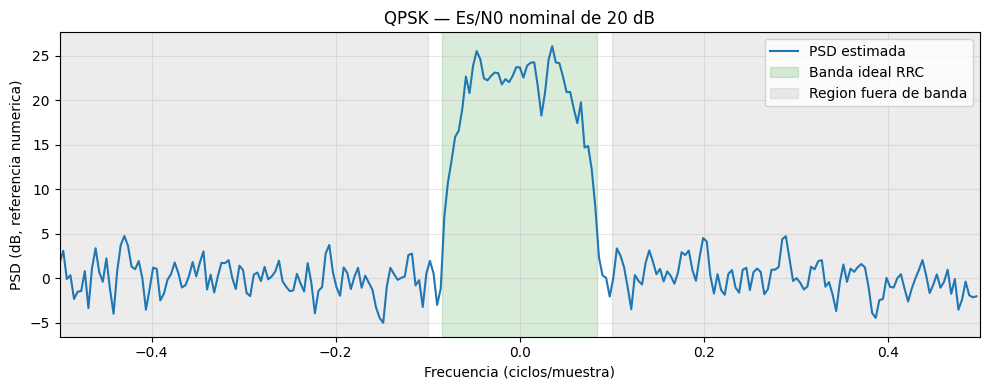

Borde ideal RRC: 0.084375 ciclos/muestra
Fuera de banda: |f| > 0.1


In [21]:
# Welch estima la densidad espectral de potencia.
# fs=1 expresa las frecuencias en ciclos/muestra.
f, psd = welch(
    y,
    fs=1.0,
    window="hann",
    nperseg=256,
    noverlap=128,
    detrend=False,
    return_onesided=False,
    scaling="density"
)

# Ordenamos el eje desde frecuencias negativas a positivas.
f = np.fft.fftshift(f)
psd = np.fft.fftshift(psd)

outside = np.abs(f) > OUTSIDE_EDGE
psd_db = 10.0 * np.log10(np.maximum(psd, 1e-20))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(f, psd_db, label="PSD estimada")

ax.axvspan(
    -BAND_EDGE, BAND_EDGE,
    color="green", alpha=0.15,
    label="Banda ideal RRC"
)
ax.axvspan(
    -0.5, -OUTSIDE_EDGE,
    color="gray", alpha=0.15,
    label="Region fuera de banda"
)
ax.axvspan(
    OUTSIDE_EDGE, 0.5,
    color="gray", alpha=0.15
)

ax.set_xlim(-0.5, 0.5)
ax.set_xlabel("Frecuencia (ciclos/muestra)")
ax.set_ylabel("PSD (dB, referencia numerica)")
ax.set_title("QPSK — Es/N0 nominal de 20 dB")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
save_figure(fig, "04_banda_ocupada_train")
plt.show()

print("Borde ideal RRC: {:.6f} ciclos/muestra".format(BAND_EDGE))
print("Fuera de banda: |f| > {}".format(OUTSIDE_EDGE))

## 4. Estadístico con la FFT completa de detection.py

La función calcula la potencia media por bin dentro y fuera de banda y devuelve su cociente. **T es adimensional**; su representación en dB es `10 * log10(T)` y no equivale directamente a Es/N0.

In [22]:
T = float(calcular_T(y))
if not np.isfinite(T) or T <= 0:
    raise ValueError("T debe ser positivo y finito.")
T_db = 10.0 * np.log10(T)
print("Estadistico T: {:.6f}".format(T))
print("Estadistico en dB: {:.2f} dB".format(T_db))

Estadistico T: 135.883560
Estadistico en dB: 21.33 dB


## 5. Comprobar invariancia frente a la ganancia

Multiplicar toda la observación por 10 multiplica ambas potencias por 100, por lo que su cociente debe mantenerse dentro de la precisión numérica.

In [23]:
T_original = float(calcular_T(y))
T_amplificada = float(calcular_T(10.0 * y))
print("T original:   {:.8f}".format(T_original))
print("T con y x 10: {:.8f}".format(T_amplificada))
assert np.isclose(T_original, T_amplificada, rtol=1e-6, atol=0.0), \
    "T cambio al amplificar la observacion."
print("Comprobacion correcta: T es invariante dentro de la tolerancia numerica.")

T original:   135.88356018
T con y x 10: 135.88356018
Comprobacion correcta: T es invariante dentro de la tolerancia numerica.


## 6. Distribución teórica bajo ruido puro

Para ruido blanco gaussiano complejo circular, la FFT completa sin ventana adicional produce potencias de bins independientes y exponenciales. Bajo H0 (solo ruido), T sigue una F con `2*K_inside` y `2*K_outside` grados de libertad. Con 1024 muestras y estas bandas: 173 bins dentro, 819 fuera, 32 de guarda; F(346, 1638). La ganancia común se cancela.

In [24]:
frequencies = np.fft.fftfreq(N_SAMPLES, d=1.0)

K_inside = int(np.count_nonzero(np.abs(frequencies) <= BAND_EDGE))
K_outside = int(np.count_nonzero(np.abs(frequencies) > OUTSIDE_EDGE))

df_inside = 2 * K_inside
df_outside = 2 * K_outside

# Distribucion teorica del estadistico bajo ruido puro.
T_noise_distribution = f_distribution(df_inside, df_outside)

print("Bins dentro: {}".format(K_inside),end="\n\n")
print("Bins fuera: {}".format(K_outside),end="\n\n")
print("T bajo ruido: F({}, {})".format(df_inside, df_outside),end="\n\n")
print("Media teorica: {:.6f}".format(T_noise_distribution.mean()))

Bins dentro: 173

Bins fuera: 819

T bajo ruido: F(346, 1638)

Media teorica: 1.001222


In [25]:
assert K_inside == detection.K_INSIDE and K_outside == detection.K_OUTSIDE, \
    "Los bins del notebook no coinciden con src/detection.py"
print("Comprobacion correcta: los bins coinciden con detection.py")

Comprobacion correcta: los bins coinciden con detection.py


## 7. Umbral analítico para una falsa alarma del 1 %

Se fija gamma como el cuantil 0.99 de la F, sin estimarlo ni ajustarlo con train. Decidimos «hay señal» si T > gamma; en caso contrario, «no se detecta señal». No detectar señal no garantiza que esté ausente.

In [26]:
detectar_senal = detection.detectar_senal
gamma = detection.GAMMA
P_FA = detection.P_FA
T_noise_distribution = detection.T_NOISE_DISTRIBUTION

print("Umbral gamma: {:.6f}".format(gamma))
print("P_fa teorica: {:.4f}".format(T_noise_distribution.sf(gamma)))
print("Se detecta senal en la observacion QPSK:", detectar_senal(y))

Umbral gamma: 1.208423
P_fa teorica: 0.0100
Se detecta senal en la observacion QPSK: True


## 8. Histograma de ruido frente a la teoría

Usamos las observaciones etiquetadas como ruido de train para una comprobación descriptiva. El umbral ya está fijado por la teoría y no se modifica con este histograma. `density=True` permite comparar áreas del histograma y de la densidad F. La región a la derecha de gamma representa falsas alarmas bajo H0.

Figura guardada: 06_T_ruido_histograma_vs_teoria


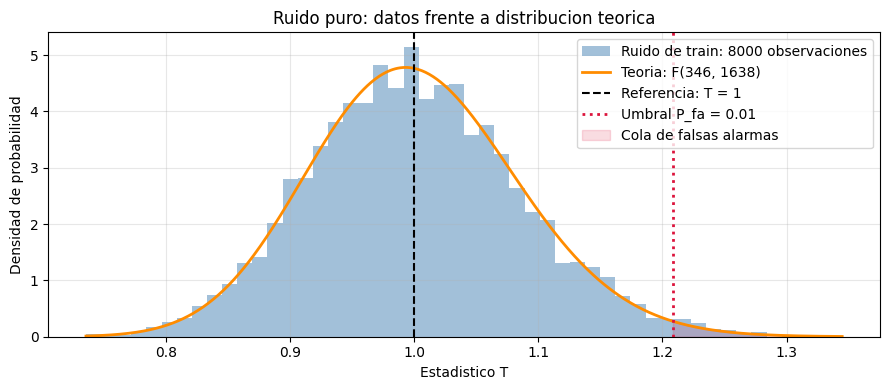

Observaciones de ruido: 8000
Media empirica: 1.000979
Media teorica:  1.001222
Desviacion estandar empirica: 0.085406
Desviacion estandar teorica:  0.083837


In [27]:
# Seleccionar las observaciones de ruido de train.
X_train = datasets["train"]["X"]
metadata_train = datasets["train"]["metadata"]

T_noise = []

for index, row in enumerate(metadata_train):
    if row["mod"] == "ruido":
        iq = X_train[index]
        y_noise = iq[0] + 1j * iq[1]

        T_noise.append(calcular_T(y_noise))

T_noise = np.asarray(T_noise, dtype=np.float64)

if T_noise.size == 0 or not np.all(np.isfinite(T_noise)):
    raise ValueError("No hay estadisticos de ruido validos.")

# Cubrir los datos observados y la parte central de la curva teorica.
t_min = min(T_noise.min(), T_noise_distribution.ppf(0.001))
t_max = max(T_noise.max(), T_noise_distribution.ppf(0.999), gamma)

t_values = np.linspace(t_min, t_max, 600)
density = T_noise_distribution.pdf(t_values)

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    T_noise,
    bins=50,
    density=True,
    alpha=0.5,
    color="steelblue",
    label="Ruido de train: {} observaciones".format(T_noise.size)
)

ax.plot(
    t_values,
    density,
    color="darkorange",
    linewidth=2,
    label="Teoria: F({}, {})".format(df_inside, df_outside)
)

ax.axvline(
    1.0,
    color="black",
    linestyle="--",
    label="Referencia: T = 1"
)

ax.axvline(gamma, color="crimson", linestyle=":", linewidth=2,
           label="Umbral P_fa = 0.01")
tail_values = np.linspace(gamma, t_max, 200)
ax.fill_between(tail_values, T_noise_distribution.pdf(tail_values),
                color="crimson", alpha=0.15, label="Cola de falsas alarmas")
ax.set_xlabel("Estadistico T")
ax.set_ylabel("Densidad de probabilidad")
ax.set_title("Ruido puro: datos frente a distribucion teorica")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
save_figure(fig, "06_T_ruido_histograma_vs_teoria")
plt.show()

print("Observaciones de ruido: {}".format(T_noise.size))
print("Media empirica: {:.6f}".format(T_noise.mean()))
print("Media teorica:  {:.6f}".format(T_noise_distribution.mean()))
print("Desviacion estandar empirica: {:.6f}".format(T_noise.std(ddof=1)))
print("Desviacion estandar teorica:  {:.6f}".format(T_noise_distribution.std()))

La coincidencia visual es una comprobación del modelo de ruido, no una garantía de detección de las modulaciones. El siguiente paso será medir falsas alarmas y detecciones en datos independientes, conservando gamma fijo.

In [28]:
#comprobacion independiente de la probabilidad de falsa alarma
N_TRIALS = 100000
VALIDATION_SEED = 20261110 #distintas para train,val,test
rng_validation = np.random.default_rng(VALIDATION_SEED)

false_alarms = 0

for i in range(N_TRIALS):
    amp = 10**rng_validation.uniform(-1.0,1.0) #dist de ganancia que en el dataset 
    
    noise = (
        rng_validation.standard_normal(N_SAMPLES)
        + 1j * rng_validation.standard_normal(N_SAMPLES)
    ) / np.sqrt(2.0)
    
    observation = noise_only(N_SAMPLES, rng_validation, amp=amp)
    # Bajo ruido puro, declarar "hay señal" es una falsa alarma.
    false_alarms += int(detectar_senal(observation))
    
    if (i + 1) % 20000 == 0:
        print("Procesadas: {} / {}".format(i + 1, N_TRIALS))

p_fa_observed = false_alarms / float(N_TRIALS)

print("\nSemilla: {}".format(VALIDATION_SEED))
print("Umbral fijo: {:.6f}".format(gamma))
print("Falsas alarmas: {} / {}".format(false_alarms, N_TRIALS))
print("P_fa observada: {:.5f}".format(p_fa_observed))
print("P_fa teorica: {:.5f}".format(P_FA))

assert 0.008 <= p_fa_observed <= 0.012, \
    "P_fa fuera del intervalo esperado: revisar la implementacion."

print("Comprobacion correcta: P_fa esta entre 0.008 y 0.012.")

Procesadas: 20000 / 100000
Procesadas: 40000 / 100000
Procesadas: 60000 / 100000
Procesadas: 80000 / 100000
Procesadas: 100000 / 100000

Semilla: 20261110
Umbral fijo: 1.208423
Falsas alarmas: 987 / 100000
P_fa observada: 0.00987
P_fa teorica: 0.01000
Comprobacion correcta: P_fa esta entre 0.008 y 0.012.


In [29]:
# Cargar validacion sin modificar gamma.
X_val = np.load(
    str(DATA_DIR / "val" / "X.npy"),
    mmap_mode="r",
    allow_pickle=False
)

with (DATA_DIR / "val" / "meta.csv").open(
    "r", newline="", encoding="utf-8"
) as file:
    metadata_val = list(csv.DictReader(file))

if X_val.ndim != 3 or X_val.shape[1:] != (2, N_SAMPLES):
    raise ValueError("Forma incorrecta de X_val.")

if len(X_val) != len(metadata_val):
    raise ValueError("X_val y meta.csv tienen distinta cantidad de observaciones.")

MODULATIONS = ("BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "16APSK")
ESN0_LEVELS = np.arange(-10, 22, 2)

totals = np.zeros(len(ESN0_LEVELS), dtype=np.int64)
detections = np.zeros(len(ESN0_LEVELS), dtype=np.int64)
counts_per_pair = {}
level_index = {
    float(level): i for i, level in enumerate(ESN0_LEVELS)
}

for index, row in enumerate(metadata_val):
    mod = row["mod"]

    # El ruido puro se utiliza para P_fa, no para P_d.
    if mod == "ruido":
        continue

    if mod not in MODULATIONS:
        raise ValueError("Modulacion desconocida: {}".format(mod))

    esn0 = float(row["snr_db"])

    if esn0 not in level_index:
        raise ValueError("Es/N0 inesperado: {}".format(esn0))

    position = level_index[esn0]
    iq = X_val[index]
    observation = iq[0] + 1j * iq[1]

    if not np.all(np.isfinite(observation)):
        raise ValueError("Observacion no finita en el indice {}.".format(index))

    totals[position] += 1
    detections[position] += int(detectar_senal(observation))

    pair = (mod, esn0)
    counts_per_pair[pair] = counts_per_pair.get(pair, 0) + 1

# Verificar el diseño de val: 100 observaciones por modulacion y Es/N0.
for mod in MODULATIONS:
    for level in ESN0_LEVELS:
        if counts_per_pair.get((mod, float(level)), 0) != 100:
            raise ValueError(
                "Se esperaban 100 observaciones para {} a {} dB.".format(
                    mod, level
                )
            )

pd_observed = detections / totals.astype(np.float64)

print("Umbral fijo gamma: {:.6f}".format(gamma))
print("\nEs/N0 (dB) | Detectadas / Total | P_d")

for level, detected, total, pd_value in zip(
    ESN0_LEVELS, detections, totals, pd_observed
):
    print(
        "{:>10} | {:>6} / {:>5}     | {:.4f}".format(
            level, detected, total, pd_value
        )
    )

Umbral fijo gamma: 1.208423

Es/N0 (dB) | Detectadas / Total | P_d
       -10 |     67 /   600     | 0.1117
        -8 |    117 /   600     | 0.1950
        -6 |    230 /   600     | 0.3833
        -4 |    300 /   600     | 0.5000
        -2 |    367 /   600     | 0.6117
         0 |    459 /   600     | 0.7650
         2 |    499 /   600     | 0.8317
         4 |    531 /   600     | 0.8850
         6 |    565 /   600     | 0.9417
         8 |    572 /   600     | 0.9533
        10 |    587 /   600     | 0.9783
        12 |    593 /   600     | 0.9883
        14 |    596 /   600     | 0.9933
        16 |    600 /   600     | 1.0000
        18 |    599 /   600     | 0.9983
        20 |    600 /   600     | 1.0000


Figura guardada: 07_pd_vs_esn0_val


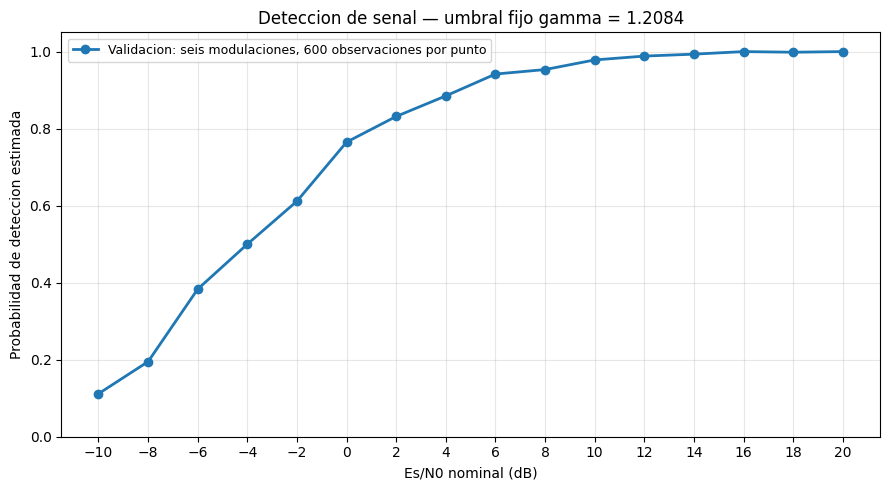

Figuras guardadas en: /home/lcmj2803/coms_proyecto2/figs/deteccion


In [30]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    ESN0_LEVELS,
    pd_observed,
    marker="o",
    linewidth=2,
    label="Validacion: seis modulaciones, 600 observaciones por punto"
)

ax.set_xlabel("Es/N0 nominal (dB)")
ax.set_ylabel("Probabilidad de deteccion estimada")
ax.set_title(
    "Deteccion de senal — umbral fijo gamma = {:.4f}".format(gamma)
)
ax.set_xticks(ESN0_LEVELS)
ax.set_ylim(0.0, 1.05)
ax.grid(alpha=0.3)
ax.legend(loc="best", fontsize=9)

plt.tight_layout()
save_figure(fig, "07_pd_vs_esn0_val")
plt.show()

print("Figuras guardadas en:", FIG_DIR)

## Lectura de la curva P_d

**Qué muestra.** Para cada Es/N0, la fracción de señales de validación que el
detector declaró como «hay señal». El umbral gamma no se tocó: es el mismo que
da una falsa alarma del 1 %.

**Resultado.** Con señal fuerte (10 dB o más) el detector acierta al menos el
98 % de las veces. En 0 dB acierta el 77 %. En −10 dB solo el 11 %: ahí la
señal está tan enterrada en el ruido que casi no se distingue de él.

**Por qué sube tan despacio.** La curva tarda unos 20 dB en pasar de 0.1 a
0.98. La causa no es el detector sino el canal. El eje horizontal es el Es/N0
*nominal*, el que se pidió al generar la señal. Pero el canal Rayleigh atenúa
cada observación de forma aleatoria, así que la señal que realmente llega
puede ser mucho más débil que la nominal. Por eso incluso a 10 dB nominales
hay un 2 % de fallos: son observaciones que cayeron en un desvanecimiento
profundo.

**Precisión.** Cada punto sale de 600 observaciones, lo que da un error de
unos ±0.04 en la zona media de la curva. Las diferencias pequeñas entre puntos
vecinos (por ejemplo, 16 y 18 dB) no son significativas.

**Límite.** El detector supone sps = 8 y beta = 0.35. Con otro ancho de banda,
las zonas «dentro» y «fuera» de banda ya no corresponden y habría que
recalcularlas.

In [31]:
# Recoger Es/N0 instantaneo y decision del detector.
instant_values = []
instant_decisions = []

for index, row in enumerate(metadata_val):
    if row["mod"] == "ruido":
        continue

    instant_db = float(row["snr_inst_db"])

    if not np.isfinite(instant_db):
        raise ValueError(
            "snr_inst_db no valido en la observacion {}.".format(index)
        )

    iq = X_val[index]
    observation = iq[0] + 1j * iq[1]

    instant_values.append(instant_db)
    instant_decisions.append(int(detectar_senal(observation)))

instant_values = np.asarray(instant_values, dtype=np.float64)
instant_decisions = np.asarray(instant_decisions, dtype=np.int64)

if instant_values.size == 0:
    raise ValueError("No se encontraron observaciones con senal.")

# Intervalos de 2 dB que cubren todos los valores observados.
# El fading puede producir valores fuera del rango nominal [-10, 20].
BIN_WIDTH_DB = 2.0

lower = BIN_WIDTH_DB * np.floor(instant_values.min() / BIN_WIDTH_DB)
upper = BIN_WIDTH_DB * (
    np.floor(instant_values.max() / BIN_WIDTH_DB) + 1
)

bin_count = int(round((upper - lower) / BIN_WIDTH_DB))
bin_edges = lower + BIN_WIDTH_DB * np.arange(bin_count + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0

# Total de señales y cantidad detectada en cada intervalo.
totals_inst, _ = np.histogram(
    instant_values, bins=bin_edges
)

detections_inst, _ = np.histogram(
    instant_values,
    bins=bin_edges,
    weights=instant_decisions
)

# Los intervalos vacios quedan como NaN, no como P_d = 0.
pd_inst = np.full(len(totals_inst), np.nan, dtype=np.float64)
nonempty = totals_inst > 0
pd_inst[nonempty] = (
    detections_inst[nonempty] / totals_inst[nonempty].astype(np.float64)
)

assert totals_inst.sum() == len(instant_values)

print("Umbral fijo gamma: {:.6f}".format(gamma))
print("\nIntervalo (dB) | Detectadas / Total | P_d")

for i in np.flatnonzero(nonempty):
    print(
        "[{:6.1f}, {:6.1f}) | {:5d} / {:5d} | {:.4f}".format(
            bin_edges[i],
            bin_edges[i + 1],
            int(detections_inst[i]),
            int(totals_inst[i]),
            pd_inst[i]
        )
    )

Umbral fijo gamma: 1.208423

Intervalo (dB) | Detectadas / Total | P_d
[ -40.0,  -38.0) |     0 /     1 | 0.0000
[ -38.0,  -36.0) |     0 /     1 | 0.0000
[ -36.0,  -34.0) |     0 /     1 | 0.0000
[ -34.0,  -32.0) |     0 /     2 | 0.0000
[ -32.0,  -30.0) |     0 /     2 | 0.0000
[ -30.0,  -28.0) |     0 /     4 | 0.0000
[ -28.0,  -26.0) |     0 /    21 | 0.0000
[ -26.0,  -24.0) |     0 /    12 | 0.0000
[ -24.0,  -22.0) |     1 /    37 | 0.0270
[ -22.0,  -20.0) |     2 /    54 | 0.0370
[ -20.0,  -18.0) |     1 /    75 | 0.0133
[ -18.0,  -16.0) |     2 /   101 | 0.0198
[ -16.0,  -14.0) |     6 /   200 | 0.0300
[ -14.0,  -12.0) |    12 /   279 | 0.0430
[ -12.0,  -10.0) |    17 /   420 | 0.0405
[ -10.0,   -8.0) |    51 /   471 | 0.1083
[  -8.0,   -6.0) |   138 /   568 | 0.2430
[  -6.0,   -4.0) |   345 /   595 | 0.5798
[  -4.0,   -2.0) |   543 /   592 | 0.9172
[  -2.0,    0.0) |   568 /   568 | 1.0000
[   0.0,    2.0) |   570 /   570 | 1.0000
[   2.0,    4.0) |   572 /   572 | 1.0000
[   4

Figura guardada: 08_pd_vs_snr_inst_db_val


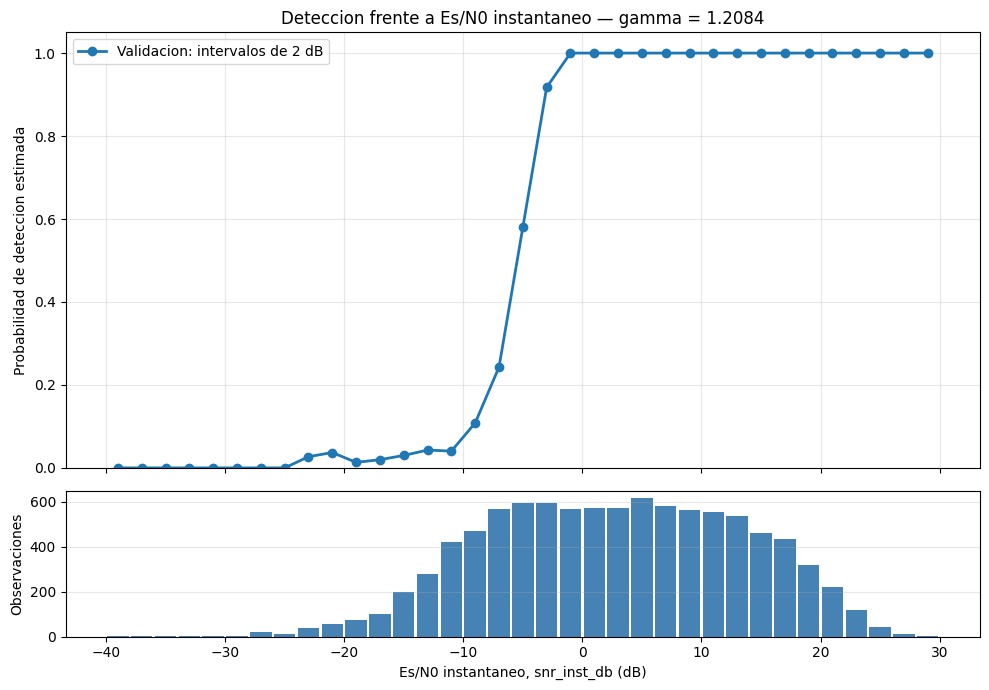

In [32]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

axes[0].plot(
    bin_centers,
    pd_inst,
    marker="o",
    linewidth=2,
    label="Validacion: intervalos de 2 dB"
)

axes[0].set_ylabel("Probabilidad de deteccion estimada")
axes[0].set_ylim(0.0, 1.05)
axes[0].set_title(
    "Deteccion frente a Es/N0 instantaneo — gamma = {:.4f}".format(gamma)
)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(
    bin_centers,
    totals_inst,
    width=0.9 * BIN_WIDTH_DB,
    color="steelblue"
)

axes[1].set_xlabel("Es/N0 instantaneo, snr_inst_db (dB)")
axes[1].set_ylabel("Observaciones")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
save_figure(fig, "08_pd_vs_snr_inst_db_val")
plt.show()

Esta curva agrupa las señales de validación según snr_inst_db, en intervalos de 2 dB, manteniendo fijo el umbral del detector. En nuestro generador, este metadato representa el Es/N0 instantáneo después del fading, referido a la potencia esperada del ruido. A diferencia del Es/N0 nominal, refleja las variaciones de energía introducidas por el canal. Los intervalos contienen distintas cantidades de observaciones; los puntos con pocos casos tienen mayor incertidumbre. Los intervalos vacíos no se interpretan como detección nula.

Parte A. QPSK a 10 dB, sin fading
Observaciones: 200
Mediana del SNR estimado: 10.124 dB
Diferencia máxima al multiplicar por A = 0.1 y A = 10: 1.491e-07 dB
Diferencia máxima con CFO = 1e-4 y fase aleatoria: 5.313e-03 dB
Estimadas 2000/9600 señales de val
Estimadas 4000/9600 señales de val
Estimadas 6000/9600 señales de val
Estimadas 8000/9600 señales de val
Figura guardada: 09_m2m4_sesgo


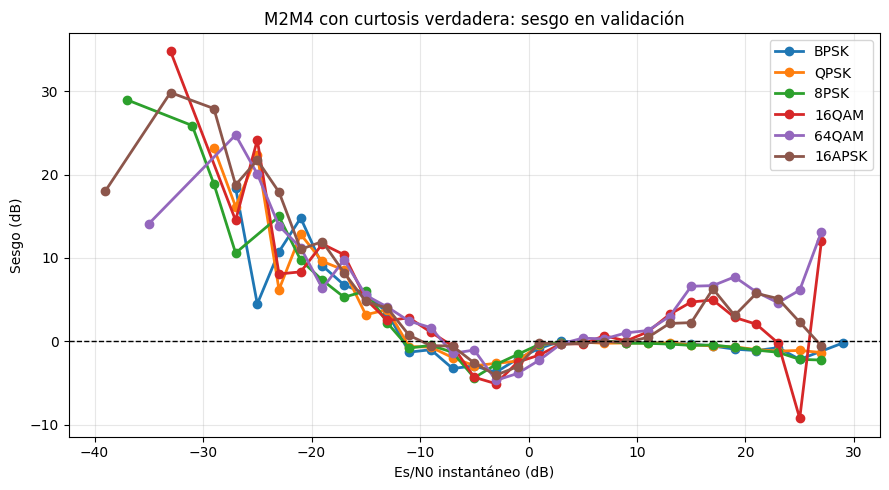

Figura guardada: 10_m2m4_rmse


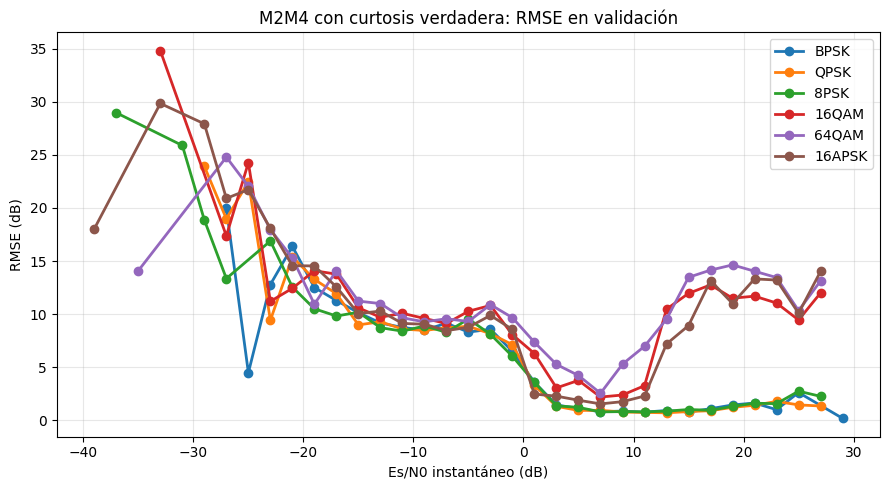

Figura guardada: 11_m2m4_ciega_vs_curtosis_16qam


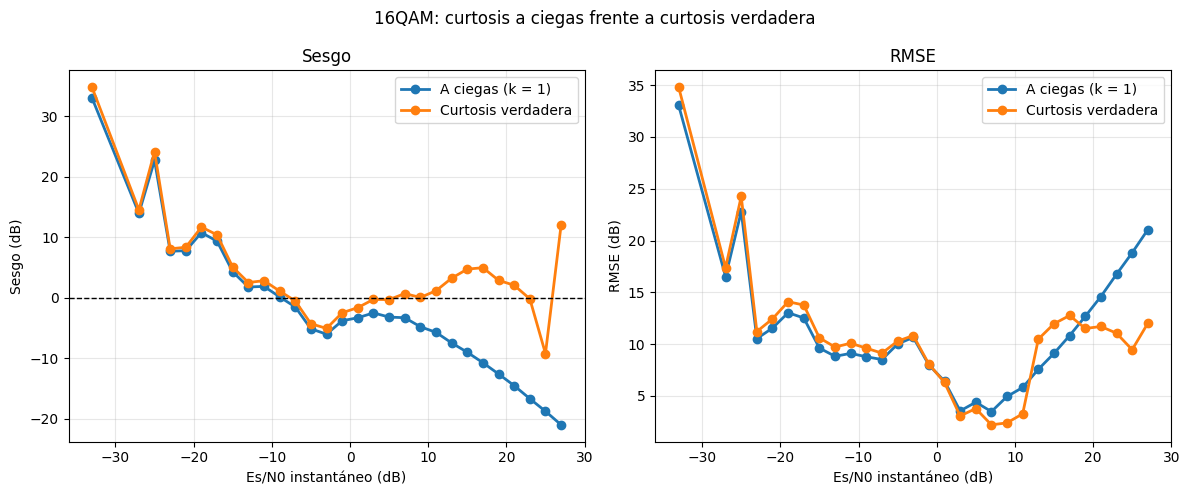


Sesgo con curtosis verdadera, Es/N0 instantáneo ≥ 0 dB
Modulación |  Observaciones | Sesgo (dB) | |sesgo| < 1 dB
BPSK       |            943 |      -0.37 | sí
QPSK       |            950 |      -0.36 | sí
8PSK       |            919 |      -0.36 | sí
BPSK, QPSK y 8PSK cumplen |sesgo| < 1 dB.


In [34]:
import importlib

from src.generator import MODS, modulate, channel, cfo_phase

detection = importlib.util.module_from_spec(spec)
spec.loader.exec_module(detection)

estimar_snr_m2m4 = detection.estimar_snr_m2m4
CURTOSIS = detection.CURTOSIS

# Parte A. QPSK controlada: sin fading y sin CFO en la generación.
N_CONTROL = 200
SNR_CONTROL_DB = 10.0
GAIN_TOLERANCE_DB = 1e-4
CFO_TOLERANCE_DB = 0.05

rng_m2m4 = np.random.default_rng(0)
control_estimates = []
gain_differences = []
cfo_differences = []

for _ in range(N_CONTROL):
    waveform = modulate(
        "QPSK",
        detection.N_SAMPLES,
        rng_m2m4,
        random_timing=True
    )
    observed, _meta = channel(
        waveform,
        rng_m2m4,
        snr_db=SNR_CONTROL_DB,
        fading=False,
        cfo=0.0,
        phase=0.0,
        amp=1.0
    )
    estimate = estimar_snr_m2m4(
        observed,
        kurtosis=CURTOSIS["QPSK"]
    )
    control_estimates.append(estimate)

    for gain in (0.1, 10.0):
        scaled_estimate = estimar_snr_m2m4(
            gain * observed,
            kurtosis=CURTOSIS["QPSK"]
        )
        gain_differences.append(abs(scaled_estimate - estimate))

    phase = float(rng_m2m4.uniform(0.0, 2.0 * np.pi))
    rotated = cfo_phase(observed, cfo=1e-4, phase=phase)
    rotated_estimate = estimar_snr_m2m4(
        rotated,
        kurtosis=CURTOSIS["QPSK"]
    )
    cfo_differences.append(abs(rotated_estimate - estimate))

control_estimates = np.asarray(control_estimates, dtype=np.float64)
median_snr = float(np.median(control_estimates))
max_gain_difference = float(np.max(gain_differences))
max_cfo_difference = float(np.max(cfo_differences))

print("Parte A. QPSK a {:.0f} dB, sin fading".format(SNR_CONTROL_DB))
print("Observaciones: {}".format(N_CONTROL))
print("Mediana del SNR estimado: {:.3f} dB".format(median_snr))
print(
    "Diferencia máxima al multiplicar por A = 0.1 y A = 10: {:.3e} dB".format(
        max_gain_difference
    )
)
print(
    "Diferencia máxima con CFO = 1e-4 y fase aleatoria: {:.3e} dB".format(
        max_cfo_difference
    )
)

assert abs(median_snr - SNR_CONTROL_DB) < 1.0, (
    "La mediana {:.3f} dB no está a menos de 1 dB de {:.0f} dB.".format(
        median_snr, SNR_CONTROL_DB
    )
)
assert max_gain_difference < GAIN_TOLERANCE_DB, (
    "La ganancia A cambió la estimación en {:.3e} dB.".format(
        max_gain_difference
    )
)
assert max_cfo_difference < CFO_TOLERANCE_DB, (
    "El CFO y la fase cambiaron la estimación en {:.3e} dB.".format(
        max_cfo_difference
    )
)

# Parte B. Validación: referencia snr_inst_db, no el Es/N0 nominal.
X_val_m2m4 = np.load(
    str(DATA_DIR / "val" / "X.npy"),
    mmap_mode="r",
    allow_pickle=False
)
with (DATA_DIR / "val" / "meta.csv").open(
    "r", newline="", encoding="utf-8"
) as file:
    metadata_m2m4 = list(csv.DictReader(file))

if X_val_m2m4.shape[0] != len(metadata_m2m4):
    raise ValueError("X.npy y meta.csv de val no coinciden.")

mod_names = []
snr_inst = []
snr_blind = []
snr_true_k = []

for index, row in enumerate(metadata_m2m4):
    if row["mod"] == "ruido":
        continue

    iq = X_val_m2m4[index]
    observation = iq[0] + 1j * iq[1]
    modulation = row["mod"]
    reference = float(row["snr_inst_db"])

    if not np.isfinite(reference):
        raise ValueError(
            "snr_inst_db no válido en la observación {}.".format(index)
        )

    mod_names.append(modulation)
    snr_inst.append(reference)
    snr_blind.append(
        estimar_snr_m2m4(observation, kurtosis=1.0)
    )
    snr_true_k.append(
        estimar_snr_m2m4(
            observation,
            kurtosis=CURTOSIS[modulation]
        )
    )

    if len(mod_names) % 2000 == 0:
        print(
            "Estimadas {}/9600 señales de val".format(len(mod_names)),
            flush=True
        )

mod_names = np.asarray(mod_names)
snr_inst = np.asarray(snr_inst, dtype=np.float64)
snr_blind = np.asarray(snr_blind, dtype=np.float64)
snr_true_k = np.asarray(snr_true_k, dtype=np.float64)

assert snr_inst.shape[0] == 9600, (
    "Se esperaban 9600 señales; hay {}.".format(snr_inst.shape[0])
)

BIN_WIDTH_DB = 2.0
lower = BIN_WIDTH_DB * np.floor(snr_inst.min() / BIN_WIDTH_DB)
upper = BIN_WIDTH_DB * (np.floor(snr_inst.max() / BIN_WIDTH_DB) + 1)
bin_count = int(round((upper - lower) / BIN_WIDTH_DB))
bin_edges = lower + BIN_WIDTH_DB * np.arange(bin_count + 1)


def metrics_by_bin(reference, estimated):
    bin_ids = np.digitize(reference, bin_edges) - 1
    bin_ids = np.clip(bin_ids, 0, bin_count - 1)

    centers = []
    biases = []
    rmses = []

    for bin_index in range(bin_count):
        mask = bin_ids == bin_index
        count = int(np.count_nonzero(mask))
        if count == 0:
            continue

        error = estimated[mask] - reference[mask]
        centers.append(
            0.5 * (bin_edges[bin_index] + bin_edges[bin_index + 1])
        )
        biases.append(float(np.mean(error)))
        rmses.append(float(np.sqrt(np.mean(error ** 2))))

    return (
        np.asarray(centers),
        np.asarray(biases),
        np.asarray(rmses)
    )


fig, ax = plt.subplots(figsize=(9, 5))

for modulation in MODS:
    mask = mod_names == modulation
    centers, biases, _rmses = metrics_by_bin(
        snr_inst[mask], snr_true_k[mask]
    )
    ax.plot(
        centers,
        biases,
        marker="o",
        linewidth=2,
        label=modulation
    )

ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Es/N0 instantáneo (dB)")
ax.set_ylabel("Sesgo (dB)")
ax.set_title("M2M4 con curtosis verdadera: sesgo en validación")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure(fig, "09_m2m4_sesgo")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

for modulation in MODS:
    mask = mod_names == modulation
    centers, _biases, rmses = metrics_by_bin(
        snr_inst[mask], snr_true_k[mask]
    )
    ax.plot(
        centers,
        rmses,
        marker="o",
        linewidth=2,
        label=modulation
    )

ax.set_xlabel("Es/N0 instantáneo (dB)")
ax.set_ylabel("RMSE (dB)")
ax.set_title("M2M4 con curtosis verdadera: RMSE en validación")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure(fig, "10_m2m4_rmse")
plt.show()

qam_mask = mod_names == "16QAM"
centers_blind, bias_blind, rmse_blind = metrics_by_bin(
    snr_inst[qam_mask], snr_blind[qam_mask]
)
centers_true, bias_true, rmse_true = metrics_by_bin(
    snr_inst[qam_mask], snr_true_k[qam_mask]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

axes[0].plot(
    centers_blind,
    bias_blind,
    marker="o",
    linewidth=2,
    label="A ciegas (k = 1)"
)
axes[0].plot(
    centers_true,
    bias_true,
    marker="o",
    linewidth=2,
    label="Curtosis verdadera"
)
axes[0].axhline(0.0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("Es/N0 instantáneo (dB)")
axes[0].set_ylabel("Sesgo (dB)")
axes[0].set_title("Sesgo")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    centers_blind,
    rmse_blind,
    marker="o",
    linewidth=2,
    label="A ciegas (k = 1)"
)
axes[1].plot(
    centers_true,
    rmse_true,
    marker="o",
    linewidth=2,
    label="Curtosis verdadera"
)
axes[1].set_xlabel("Es/N0 instantáneo (dB)")
axes[1].set_ylabel("RMSE (dB)")
axes[1].set_title("RMSE")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle("16QAM: curtosis a ciegas frente a curtosis verdadera")
plt.tight_layout()
save_figure(fig, "11_m2m4_ciega_vs_curtosis_16qam")
plt.show()

print(
    "\nSesgo con curtosis verdadera, Es/N0 instantáneo ≥ 0 dB"
)
print(
    "{:<10} | {:>14} | {:>10} | {}".format(
        "Modulación",
        "Observaciones",
        "Sesgo (dB)",
        "|sesgo| < 1 dB"
    )
)

psk_meets = []

for modulation in ("BPSK", "QPSK", "8PSK"):
    mask = (mod_names == modulation) & (snr_inst >= 0.0)
    count = int(np.count_nonzero(mask))
    bias = float(np.mean(snr_true_k[mask] - snr_inst[mask]))
    meets = abs(bias) < 1.0
    psk_meets.append(meets)
    print(
        "{:<10} | {:>14} | {:>10.2f} | {}".format(
            modulation,
            count,
            bias,
            "sí" if meets else "no"
        )
    )

if all(psk_meets):
    print("BPSK, QPSK y 8PSK cumplen |sesgo| < 1 dB.")
else:
    print("BPSK, QPSK y 8PSK no cumplen todas |sesgo| < 1 dB.")


Parte A. Es/N0 = 10 dB, sin fading
QPSK: 200 observaciones
  Mediana del SNR estimado: 9.972 dB
  Diferencia máxima al multiplicar por A: 1.626e-06 dB
  Diferencia máxima con fase y CFO = 1e-4: 3.786e-02 dB
16QAM: 200 observaciones
  Mediana del SNR estimado: 10.020 dB
  Diferencia máxima al multiplicar por A: 2.039e-06 dB
  Diferencia máxima con fase y CFO = 1e-4: 3.373e-02 dB
Parte B. Estimando las señales de val
Estimadas 2000/9600 señales de val
Estimadas 4000/9600 señales de val
Estimadas 6000/9600 señales de val
Estimadas 8000/9600 señales de val
Figura guardada: 12_espectral_sesgo


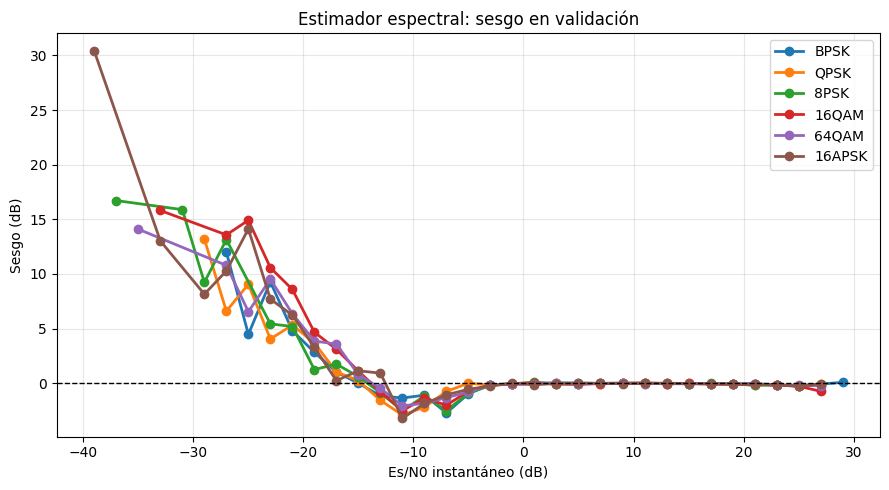

Figura guardada: 13_espectral_rmse


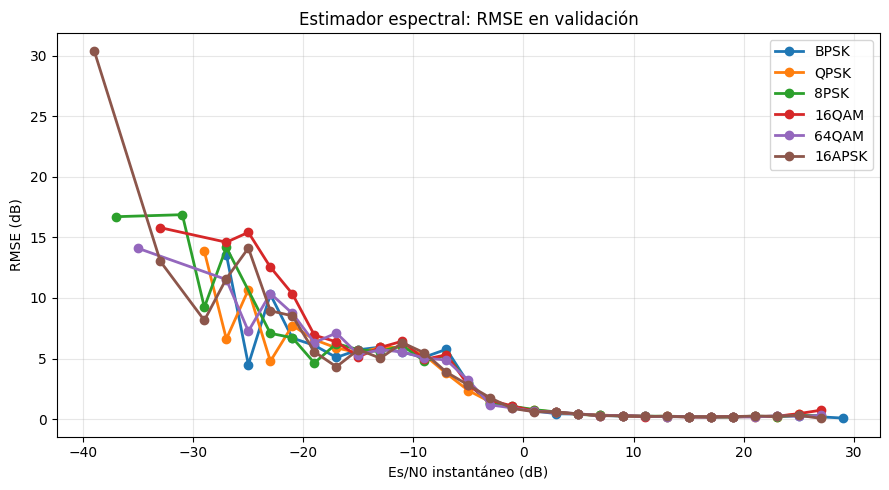

Figura guardada: 14_espectral_vs_m2m4_rmse


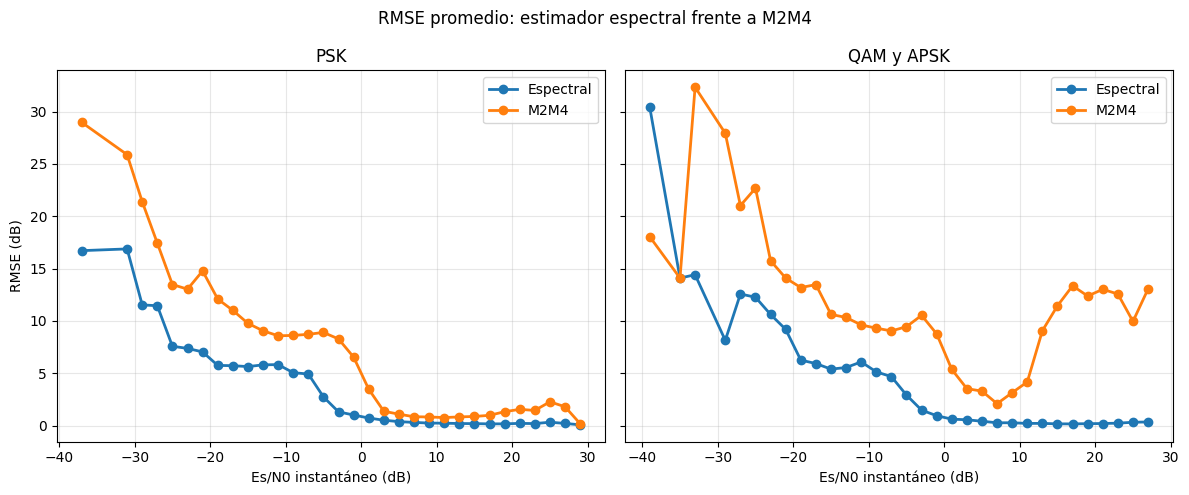


Sesgo y RMSE por rango de Es/N0 instantáneo
Rango (dB)     |      N |   Sesgo esp. |    RMSE esp. |   Sesgo M2M4 |    RMSE M2M4
[-4, 0)        |   1160 |        -0.12 |         1.24 |        -3.22 |         8.70
[0, 5)         |   1429 |        -0.02 |         0.59 |        -0.50 |         3.63
[5, 10)        |   1468 |        -0.02 |         0.31 |         0.05 |         2.36
[10, 15)       |   1328 |        -0.01 |         0.22 |         1.00 |         5.67
[15, 20)       |    979 |        -0.05 |         0.18 |         2.20 |         8.97
[20, 30)       |    392 |        -0.13 |         0.24 |         1.31 |         9.16

Sesgo del estimador espectral, Es/N0 instantáneo ≥ 0 dB
Modulación |  Observaciones | Sesgo (dB) | |sesgo| < 1 dB
BPSK       |            943 |      -0.02 | sí
QPSK       |            950 |      -0.03 | sí
8PSK       |            919 |      -0.02 | sí
16QAM      |            928 |      -0.04 | sí
64QAM      |            924 |      -0.03 | sí
16APSK     |          

In [35]:
from src.generator import MODS, modulate, channel, cfo_phase

detection = importlib.util.module_from_spec(spec)
spec.loader.exec_module(detection)

estimar_snr_espectral = detection.estimar_snr_espectral
estimar_snr_m2m4 = detection.estimar_snr_m2m4
CURTOSIS = detection.CURTOSIS

# Parte A. Misma potencia, dos modulaciones: el estimador no usa la constelación.
N_CONTROL = 200
SNR_CONTROL_DB = 10.0
GAIN_TOLERANCE_DB = 1e-4
CFO_TOLERANCE_DB = 0.1

rng_espectral = np.random.default_rng(0)

print("Parte A. Es/N0 = {:.0f} dB, sin fading".format(SNR_CONTROL_DB))

for modulation in ("QPSK", "16QAM"):
    estimates = []
    gain_differences = []
    cfo_differences = []

    for _ in range(N_CONTROL):
        waveform = modulate(
            modulation,
            detection.N_SAMPLES,
            rng_espectral,
            random_timing=True
        )
        observed, _meta = channel(
            waveform,
            rng_espectral,
            snr_db=SNR_CONTROL_DB,
            fading=False,
            cfo=0.0,
            phase=0.0,
            amp=1.0
        )
        estimate = estimar_snr_espectral(observed)
        estimates.append(estimate)

        for gain in (0.1, 10.0):
            scaled_estimate = estimar_snr_espectral(gain * observed)
            gain_differences.append(abs(scaled_estimate - estimate))

        phase = float(rng_espectral.uniform(0.0, 2.0 * np.pi))
        rotated = cfo_phase(observed, cfo=1e-4, phase=phase)
        rotated_estimate = estimar_snr_espectral(rotated)
        cfo_differences.append(abs(rotated_estimate - estimate))

    estimates = np.asarray(estimates, dtype=np.float64)
    median_snr = float(np.median(estimates))
    max_gain_difference = float(np.max(gain_differences))
    max_cfo_difference = float(np.max(cfo_differences))

    print("{}: {} observaciones".format(modulation, N_CONTROL))
    print("  Mediana del SNR estimado: {:.3f} dB".format(median_snr))
    print(
        "  Diferencia máxima al multiplicar por A: {:.3e} dB".format(
            max_gain_difference
        )
    )
    print(
        "  Diferencia máxima con fase y CFO = 1e-4: {:.3e} dB".format(
            max_cfo_difference
        )
    )

    assert abs(median_snr - SNR_CONTROL_DB) < 0.5, (
        "{}: la mediana {:.3f} dB no está a menos de 0.5 dB de {:.0f} dB.".format(
            modulation, median_snr, SNR_CONTROL_DB
        )
    )
    assert max_gain_difference < GAIN_TOLERANCE_DB, (
        "{}: la ganancia A cambió la estimación en {:.3e} dB.".format(
            modulation, max_gain_difference
        )
    )
    assert max_cfo_difference < CFO_TOLERANCE_DB, (
        "{}: la fase y el CFO cambiaron la estimación en {:.3e} dB.".format(
            modulation, max_cfo_difference
        )
    )

# Parte B. Validación: referencia snr_inst_db, no el Es/N0 nominal.
X_val_espectral = np.load(
    str(DATA_DIR / "val" / "X.npy"),
    mmap_mode="r",
    allow_pickle=False
)
with (DATA_DIR / "val" / "meta.csv").open(
    "r", newline="", encoding="utf-8"
) as file:
    metadata_espectral = list(csv.DictReader(file))

if X_val_espectral.shape[0] != len(metadata_espectral):
    raise ValueError("X.npy y meta.csv de val no coinciden.")

mod_names = []
snr_inst = []
snr_spectral = []
snr_m2m4 = []

print("Parte B. Estimando las señales de val", flush=True)

for index, row in enumerate(metadata_espectral):
    if row["mod"] == "ruido":
        continue

    iq = X_val_espectral[index]
    observation = iq[0] + 1j * iq[1]
    modulation = row["mod"]
    reference = float(row["snr_inst_db"])

    if not np.isfinite(reference):
        raise ValueError(
            "snr_inst_db no válido en la observación {}.".format(index)
        )

    mod_names.append(modulation)
    snr_inst.append(reference)
    snr_spectral.append(estimar_snr_espectral(observation))
    snr_m2m4.append(
        estimar_snr_m2m4(
            observation,
            kurtosis=CURTOSIS[modulation]
        )
    )

    if len(mod_names) % 2000 == 0:
        print(
            "Estimadas {}/9600 señales de val".format(len(mod_names)),
            flush=True
        )

mod_names = np.asarray(mod_names)
snr_inst = np.asarray(snr_inst, dtype=np.float64)
snr_spectral = np.asarray(snr_spectral, dtype=np.float64)
snr_m2m4 = np.asarray(snr_m2m4, dtype=np.float64)

assert snr_inst.shape[0] == 9600, (
    "Se esperaban 9600 señales; hay {}.".format(snr_inst.shape[0])
)

BIN_WIDTH_DB = 2.0
lower = BIN_WIDTH_DB * np.floor(snr_inst.min() / BIN_WIDTH_DB)
upper = BIN_WIDTH_DB * (np.floor(snr_inst.max() / BIN_WIDTH_DB) + 1)
bin_count = int(round((upper - lower) / BIN_WIDTH_DB))
bin_edges = lower + BIN_WIDTH_DB * np.arange(bin_count + 1)


def binned_error(reference, estimated):
    bin_ids = np.digitize(reference, bin_edges) - 1
    bin_ids = np.clip(bin_ids, 0, bin_count - 1)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bias = np.full(bin_count, np.nan)
    rmse = np.full(bin_count, np.nan)

    for bin_index in range(bin_count):
        mask = bin_ids == bin_index
        if not np.any(mask):
            continue

        error = estimated[mask] - reference[mask]
        bias[bin_index] = float(np.mean(error))
        rmse[bin_index] = float(np.sqrt(np.mean(error ** 2)))

    return centers, bias, rmse


def mean_rmse(modulations, estimated):
    curves = []

    for modulation in modulations:
        mask = mod_names == modulation
        _centers, _bias, rmse = binned_error(
            snr_inst[mask], estimated[mask]
        )
        curves.append(rmse)

    stacked = np.vstack(curves)
    count = np.sum(np.isfinite(stacked), axis=0)
    total = np.nansum(stacked, axis=0)
    averaged = np.full(bin_count, np.nan)
    valid = count > 0
    averaged[valid] = total[valid] / count[valid]
    return averaged


fig, ax = plt.subplots(figsize=(9, 5))

for modulation in MODS:
    mask = mod_names == modulation
    centers, bias, _rmse = binned_error(
        snr_inst[mask], snr_spectral[mask]
    )
    valid = np.isfinite(bias)
    ax.plot(
        centers[valid],
        bias[valid],
        marker="o",
        linewidth=2,
        label=modulation
    )

ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Es/N0 instantáneo (dB)")
ax.set_ylabel("Sesgo (dB)")
ax.set_title("Estimador espectral: sesgo en validación")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure(fig, "12_espectral_sesgo")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

for modulation in MODS:
    mask = mod_names == modulation
    centers, _bias, rmse = binned_error(
        snr_inst[mask], snr_spectral[mask]
    )
    valid = np.isfinite(rmse)
    ax.plot(
        centers[valid],
        rmse[valid],
        marker="o",
        linewidth=2,
        label=modulation
    )

ax.set_xlabel("Es/N0 instantáneo (dB)")
ax.set_ylabel("RMSE (dB)")
ax.set_title("Estimador espectral: RMSE en validación")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure(fig, "13_espectral_rmse")
plt.show()

PSK_MODS = ("BPSK", "QPSK", "8PSK")
QAM_MODS = ("16QAM", "64QAM", "16APSK")
centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

rmse_groups = (
    (
        "PSK",
        mean_rmse(PSK_MODS, snr_spectral),
        mean_rmse(PSK_MODS, snr_m2m4)
    ),
    (
        "QAM y APSK",
        mean_rmse(QAM_MODS, snr_spectral),
        mean_rmse(QAM_MODS, snr_m2m4)
    ),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for axis, (title, rmse_spectral, rmse_moments) in zip(axes, rmse_groups):
    valid_spectral = np.isfinite(rmse_spectral)
    valid_moments = np.isfinite(rmse_moments)

    axis.plot(
        centers[valid_spectral],
        rmse_spectral[valid_spectral],
        marker="o",
        linewidth=2,
        label="Espectral"
    )
    axis.plot(
        centers[valid_moments],
        rmse_moments[valid_moments],
        marker="o",
        linewidth=2,
        label="M2M4"
    )
    axis.set_xlabel("Es/N0 instantáneo (dB)")
    axis.set_title(title)
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_ylabel("RMSE (dB)")
fig.suptitle(
    "RMSE promedio: estimador espectral frente a M2M4"
)
plt.tight_layout()
save_figure(fig, "14_espectral_vs_m2m4_rmse")
plt.show()

print("\nSesgo y RMSE por rango de Es/N0 instantáneo")
print(
    "{:<14} | {:>6} | {:>12} | {:>12} | {:>12} | {:>12}".format(
        "Rango (dB)",
        "N",
        "Sesgo esp.",
        "RMSE esp.",
        "Sesgo M2M4",
        "RMSE M2M4"
    )
)

for low, high in (
    (-4.0, 0.0),
    (0.0, 5.0),
    (5.0, 10.0),
    (10.0, 15.0),
    (15.0, 20.0),
    (20.0, 30.0),
):
    mask = (snr_inst >= low) & (snr_inst < high)
    count = int(np.count_nonzero(mask))
    label = "[{:.0f}, {:.0f})".format(low, high)

    if count == 0:
        print(
            "{:<14} | {:>6} | {:>12} | {:>12} | {:>12} | {:>12}".format(
                label, count, "—", "—", "—", "—"
            )
        )
        continue

    error_spectral = snr_spectral[mask] - snr_inst[mask]
    error_m2m4 = snr_m2m4[mask] - snr_inst[mask]
    print(
        "{:<14} | {:>6} | {:>12.2f} | {:>12.2f} | {:>12.2f} | {:>12.2f}".format(
            label,
            count,
            float(np.mean(error_spectral)),
            float(np.sqrt(np.mean(error_spectral ** 2))),
            float(np.mean(error_m2m4)),
            float(np.sqrt(np.mean(error_m2m4 ** 2)))
        )
    )

print(
    "\nSesgo del estimador espectral, Es/N0 instantáneo ≥ 0 dB"
)
print(
    "{:<10} | {:>14} | {:>10} | {}".format(
        "Modulación",
        "Observaciones",
        "Sesgo (dB)",
        "|sesgo| < 1 dB"
    )
)

spectral_meets = []

for modulation in MODS:
    mask = (mod_names == modulation) & (snr_inst >= 0.0)
    count = int(np.count_nonzero(mask))
    bias = float(np.mean(snr_spectral[mask] - snr_inst[mask]))
    meets = abs(bias) < 1.0
    spectral_meets.append(meets)
    print(
        "{:<10} | {:>14} | {:>10.2f} | {}".format(
            modulation,
            count,
            bias,
            "sí" if meets else "no"
        )
    )

if all(spectral_meets):
    print(
        "El estimador espectral cumple |sesgo| < 1 dB "
        "en las 6 modulaciones."
    )
else:
    print(
        "El estimador espectral no cumple |sesgo| < 1 dB "
        "en las 6 modulaciones."
    )
